# Theme Alpha Q5 Bear Market Stress Practice

Q5 tests whether the Theme Alpha core/satellite structure survives worse historical regimes.

This notebook keeps the Q4 LowVolTrend setup fixed and studies:

- whether the expanded LVT satellite moves to cash in bad markets;
- whether core/satellite reduces drawdown versus the original three-asset RiskParity core;
- whether the core layer needs its own defensive rule.

In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q5-bear-market-stress")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0

REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2020-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
CORE_DEFENSE_MA = 120

WINDOWS = {
    "2021_to_date": ("2021-01-01", None),
    "2021_2022_bear": ("2021-02-18", "2022-10-31"),
    "2022_full": ("2022-01-01", "2022-12-31"),
    "2023_full": ("2023-01-01", "2023-12-31"),
    "2024_full": ("2024-01-01", "2024-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")

Output dir: outputs/theme-alpha-q5-bear-market-stress
End date request: 2026-06-24


## Data Loading

Use adjusted daily prices from yfinance. Assets are aligned on a union calendar and forward-filled after listing. Assets without enough history at a rebalance date are excluded from the selector/allocator for that date.

In [2]:
def download_close(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    if isinstance(df.columns, pd.MultiIndex):
        df = df.droplevel(1, axis=1)
    col = "Close" if "Close" in df.columns else "Adj Close"
    return df[col].rename(symbol)

raw_close = []
for symbol in ALL_SYMBOLS:
    raw_close.append(download_close(symbol))

close_raw = pd.concat(raw_close, axis=1).sort_index()
availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "rows": int(close_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

close = close_raw.ffill()
returns = close.pct_change(fill_method=None)

,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-23,1565
1,513100.SS,纳指100ETF,2020-01-02,2026-06-23,1566
2,518880.SS,黄金ETF,2020-01-02,2026-06-23,1565
3,512400.SS,有色金属ETF,2020-01-02,2026-06-23,1565
4,159995.SZ,芯片ETF,2020-01-20,2026-06-23,1547
5,515880.SS,通信ETF,2020-01-02,2026-06-23,1565
6,510880.SS,红利ETF,2020-01-02,2026-06-23,1565
7,159930.SZ,能源ETF,2020-01-02,2026-06-23,1543
8,512880.SS,证券ETF,2020-01-02,2026-06-23,1565
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-23,1233


## Strategy Functions

Q5 keeps Q4's LVT parameters fixed:

- 10-trading-day rebalance cadence
- MA60 trend filter
- 63-day positive momentum filter
- 60-day volatility ranking
- Top 3 selected assets
- 50% cap inside the LVT sleeve

The diagnostic defensive core is separated from the official Q4 structure. It redirects CSI 300 and Nasdaq core weights to cash when those assets are below their 120-day moving average at a rebalance date.

In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def rebalance_dates(index):
    idx = pd.DatetimeIndex(index)
    start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
    return set(pd.DatetimeIndex(idx[start::REBALANCE_DAYS]))


def enough_history(sym, loc, window):
    if loc < window:
        return False
    hist = close[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    hist = returns[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selector(universe):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return []
        valid = []
        for sym in universe:
            if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
                continue
            if not enough_return_history(sym, loc, VOL_WINDOW):
                continue
            valid.append(sym)
        if not valid:
            return []
        price = close.iloc[loc][valid]
        ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][valid].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][valid] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][valid].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(TOP_N).index.tolist()
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def build_weights(universe, selector, allocator):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def defend_core_weights(weights):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in rdates:
            loc = close.index.get_loc(date)
            base = weights.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, CORE_DEFENSE_MA) and close.at[date, sym] > close[sym].iloc[loc - CORE_DEFENSE_MA + 1:loc + 1].mean()
                if not risk_on:
                    base["CASH"] += base[sym]
                    base[sym] = 0.0
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


def expand_weights(weights, all_assets):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(all_assets) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_weights(name, sleeves):
    out = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for allocation, weights in sleeves:
        ew = expand_weights(weights, ALL_SYMBOLS)
        out += allocation * ew.reindex(close.index).ffill().fillna(0.0)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    out = out.div(total.replace(0, np.nan), axis=0).fillna(0.0)
    return out


def turnover_from_weights(signal_weights):
    actual = signal_weights[list(ALL_SYMBOLS) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_combined(name, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)]).sum(axis=1, min_count=1).fillna(0.0)
    turnover = turnover_from_weights(signal_weights)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name), "cost_bps": cost_bps}


def fixed_weight_portfolio(name, weights):
    w = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for sym, val in weights.items():
        w[sym] = val
    w["CASH"] = max(0.0, 1.0 - sum(weights.values()))
    return backtest_combined(name, w)

## Build Portfolios

The formal Q4 candidates are Core 100, expanded LVT 100, and fixed core/satellite mixes. The defensive core version is included only as a stress diagnostic.

In [4]:
core_w = build_weights(CORE_ASSETS, all_assets(CORE_ASSETS), lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None))
expanded_lvt_w = build_weights(EXPANDED_THEME, low_vol_trend_selector(EXPANDED_THEME), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, CAP))
defensive_core_w = defend_core_weights(core_w)

weights_map = {
    "Core_100": combine_weights("Core_100", [(1.0, core_w)]),
    "ExpandedLVT_100": combine_weights("ExpandedLVT_100", [(1.0, expanded_lvt_w)]),
    "Core80_ExpandedLVT20": combine_weights("Core80_ExpandedLVT20", [(0.80, core_w), (0.20, expanded_lvt_w)]),
    "Core70_ExpandedLVT30": combine_weights("Core70_ExpandedLVT30", [(0.70, core_w), (0.30, expanded_lvt_w)]),
    "Core60_ExpandedLVT40": combine_weights("Core60_ExpandedLVT40", [(0.60, core_w), (0.40, expanded_lvt_w)]),
    "Core80_ExpandedLVT20_DefCore": combine_weights("Core80_ExpandedLVT20_DefCore", [(0.80, defensive_core_w), (0.20, expanded_lvt_w)]),
}

portfolios = {name: backtest_combined(name, weights) for name, weights in weights_map.items()}
benchmarks = {
    "CSI300_100": fixed_weight_portfolio("CSI300_100", {CSI300: 1.0}),
    "NASDAQ_100": fixed_weight_portfolio("NASDAQ_100", {NASDAQ: 1.0}),
    "Gold_100": fixed_weight_portfolio("Gold_100", {GOLD: 1.0}),
    "CSI300_Gold_60_40": fixed_weight_portfolio("CSI300_Gold_60_40", {CSI300: 0.60, GOLD: 0.40}),
}
all_portfolios = {**portfolios, **benchmarks}

latest = []
avg = []
for name, weights in weights_map.items():
    latest.append({"策略": name, **{SYMBOL_NAMES.get(c, c): weights[c].iloc[-1] for c in ALL_SYMBOLS}, "现金": weights["CASH"].iloc[-1]})
    avg.append({"策略": name, **{SYMBOL_NAMES.get(c, c): weights[c].mean() for c in ALL_SYMBOLS}, "现金": weights["CASH"].mean()})
latest_weights = pd.DataFrame(latest)
average_weights = pd.DataFrame(avg)
latest_weights.to_csv(OUTPUT_DIR / "latest_weights.csv", index=False, encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights.csv", index=False, encoding="utf-8-sig")
display(latest_weights.round(4))

,策略,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,Core_100,0.4595,0.2189,0.3216,0.0,0.0000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
1,ExpandedLVT_100,0.0000,0.4293,0.0000,0.0,0.2832,0.2874,0.0,0.0,0.0,0.0,0.0,0.0
2,Core80_ExpandedLVT20,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0,0.0,0.0,0.0
3,Core70_ExpandedLVT30,0.3216,0.2820,0.2251,0.0,0.0850,0.0862,0.0,0.0,0.0,0.0,0.0,0.0
4,Core60_ExpandedLVT40,0.2757,0.3031,0.1930,0.0,0.1133,0.1150,0.0,0.0,0.0,0.0,0.0,0.0
5,Core80_ExpandedLVT20_DefCore,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0,0.0,0.0,0.0


## Diagnostics and Metrics

Use the same daily returns across strategies and export monthly behavior, underwater/recovery, and satellite cash diagnostics.

In [5]:
def period_slice(series_or_df, start, end):
    obj = series_or_df.loc[pd.Timestamp(start):]
    if end is not None:
        obj = obj.loc[:pd.Timestamp(end)]
    return obj.dropna(how="all") if isinstance(obj, pd.DataFrame) else obj.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def max_drawdown(nav):
    dd = drawdown_series(nav)
    return float(dd.min())


def longest_true_run(mask):
    longest = cur = 0
    for val in mask.astype(bool):
        if val:
            cur += 1
            longest = max(longest, cur)
        else:
            cur = 0
    return int(longest)


def recovery_summary(nav):
    nav = nav.dropna()
    if nav.empty:
        return {"水下时间占比": np.nan, "平均水下": np.nan, "最长水下天数": np.nan, "超过-10%天数": np.nan, "超过-20%天数": np.nan, "平均修复天数": np.nan, "最长修复天数": np.nan, "未修复回撤": np.nan}
    dd = drawdown_series(nav)
    underwater = dd < -1e-12
    durations = []
    start_idx = None
    for i, is_under in enumerate(underwater.values):
        if is_under and start_idx is None:
            start_idx = i
        if (not is_under) and start_idx is not None:
            durations.append(i - start_idx)
            start_idx = None
    unresolved = 0.0
    if start_idx is not None:
        unresolved = float(dd.iloc[-1])
    completed = [d for d in durations if d > 0]
    return {
        "水下时间占比": float(underwater.mean()),
        "平均水下": float(dd[underwater].mean()) if underwater.any() else 0.0,
        "最长水下天数": longest_true_run(underwater),
        "超过-10%天数": int((dd <= -0.10).sum()),
        "超过-20%天数": int((dd <= -0.20).sum()),
        "平均修复天数": float(np.mean(completed)) if completed else 0.0,
        "最长修复天数": int(max(completed)) if completed else 0,
        "未修复回撤": unresolved,
    }


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    if r.empty:
        return {"策略": name}
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    downside = r[r < 0].std(ddof=1) * np.sqrt(TRADING_DAYS)
    sortino = ann / downside if downside and downside > 0 else np.nan
    mdd = max_drawdown(nav)
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    row = {
        "策略": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "夏普": sharpe,
        "索提诺": sortino,
        "卡玛": calmar,
        "月胜率": (monthly > 0).mean(),
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最好月份": monthly.max() if len(monthly) else np.nan,
        "最差月份": monthly.min() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
    }
    row.update(recovery_summary(nav))
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.sum() / years
        row["总换手"] = t.sum()
    if weights is not None:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        row["平均现金"] = w["CASH"].mean()
        row["平均最大单资产权重"] = w[list(ALL_SYMBOLS)].max(axis=1).mean()
        row["当前最大单资产权重"] = w[list(ALL_SYMBOLS)].iloc[-1].max()
    return row


def monthly_diagnostics(name, r):
    m = r.dropna().resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = m[m > 0]
    losses = m[m < 0]
    return {
        "策略": name,
        "月份数": len(m),
        "胜率": (m > 0).mean() if len(m) else np.nan,
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最好月份": m.max() if len(m) else np.nan,
        "最差月份": m.min() if len(m) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
    }


def top_drawdown_events(nav, top_n=5):
    dd = drawdown_series(nav)
    events = []
    in_dd = False
    start = trough = None
    trough_depth = 0.0
    for date, depth in dd.items():
        if depth < -1e-12 and not in_dd:
            in_dd = True
            start = date
            trough = date
            trough_depth = depth
        elif in_dd:
            if depth < trough_depth:
                trough = date
                trough_depth = depth
            if depth >= -1e-12:
                events.append({"start": start, "trough": trough, "recovery": date, "depth": trough_depth, "days": (date - start).days})
                in_dd = False
    if in_dd:
        events.append({"start": start, "trough": trough, "recovery": pd.NaT, "depth": trough_depth, "days": (nav.index[-1] - start).days})
    return pd.DataFrame(events).sort_values("depth").head(top_n) if events else pd.DataFrame(columns=["start", "trough", "recovery", "depth", "days"])

In [6]:
def evaluate_window(window_name, start, end):
    summary_rows = []
    monthly_rows = []
    recovery_rows = []
    navs = {}
    underwater = {}
    for name, port in all_portfolios.items():
        r = period_slice(port["returns"], start, end)
        w = period_slice(port["weights"], start, end)
        t = period_slice(port["turnover"], start, end)
        nav = nav_from_returns(r)
        summary_rows.append(metrics_row(name, r, w, t))
        monthly_rows.append(monthly_diagnostics(name, r))
        recovery = {"策略": name, **recovery_summary(nav)}
        recovery_rows.append(recovery)
        navs[name] = nav
        underwater[name] = nav / nav.cummax() - 1.0
        events = top_drawdown_events(nav)
        events.to_csv(OUTPUT_DIR / f"drawdown_events_{window_name}_{name}.csv", index=False, encoding="utf-8-sig")
    summary = pd.DataFrame(summary_rows).set_index("策略")
    preferred_order = list(portfolios.keys()) + list(benchmarks.keys())
    summary = summary.reindex(preferred_order)
    monthly = pd.DataFrame(monthly_rows).set_index("策略").reindex(preferred_order)
    recovery = pd.DataFrame(recovery_rows).set_index("策略").reindex(preferred_order)
    nav_df = pd.DataFrame(navs)
    uw_df = pd.DataFrame(underwater)
    summary.to_csv(OUTPUT_DIR / f"summary_{window_name}.csv", encoding="utf-8-sig")
    monthly.to_csv(OUTPUT_DIR / f"monthly_diagnostics_{window_name}.csv", encoding="utf-8-sig")
    recovery.to_csv(OUTPUT_DIR / f"underwater_recovery_{window_name}.csv", encoding="utf-8-sig")
    nav_df.to_csv(OUTPUT_DIR / f"nav_{window_name}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_{window_name}.csv", encoding="utf-8-sig")
    return summary, monthly, recovery, nav_df, uw_df

summary_tables = {}
monthly_tables = {}
recovery_tables = {}
nav_tables = {}
underwater_tables = {}
for window_name, (start, end) in WINDOWS.items():
    summary, monthly, recovery, nav_df, uw_df = evaluate_window(window_name, start, end)
    summary_tables[window_name] = summary
    monthly_tables[window_name] = monthly
    recovery_tables[window_name] = recovery
    nav_tables[window_name] = nav_df
    underwater_tables[window_name] = uw_df
    print(f"\n=== {window_name} summary ===")
    display(summary[["累计收益", "最大回撤", "夏普", "卡玛", "最差月份", "平均现金", "年化换手"]].round(4))


=== 2021_to_date summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,平均现金,年化换手
策略,,,,,,,
Core_100,1.1506,-0.1254,1.3142,1.2523,-0.0750,0.000,1.7854
ExpandedLVT_100,1.7101,-0.2256,1.2961,0.9271,-0.0842,0.000,8.0599
Core80_ExpandedLVT20,1.2667,-0.1171,1.4150,1.4403,-0.0701,0.000,2.8910
Core70_ExpandedLVT30,1.3243,-0.1286,1.4408,1.3552,-0.0678,0.000,3.5037
Core60_ExpandedLVT40,1.3815,-0.1414,1.4505,1.2714,-0.0680,0.000,4.1373
Core80_ExpandedLVT20_DefCore,1.0539,-0.0921,1.4620,1.5949,-0.0474,0.171,4.5202
CSI300_100,0.0469,-0.4216,0.0484,0.0208,-0.0783,0.000,0.0000
NASDAQ_100,1.4846,-0.2750,0.8150,0.6884,-0.1434,0.000,0.0000
Gold_100,1.2174,-0.2855,0.9585,0.5738,-0.1129,0.000,0.0000



=== 2021_2022_bear summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,平均现金,年化换手
策略,,,,,,,
Core_100,-0.1155,-0.1223,-0.6796,-0.5904,-0.0611,0.0000,1.3770
ExpandedLVT_100,-0.0629,-0.2256,-0.2235,-0.1722,-0.0842,0.0000,9.5907
Core80_ExpandedLVT20,-0.1028,-0.1158,-0.5923,-0.5531,-0.0645,0.0000,2.8883
Core70_ExpandedLVT30,-0.0968,-0.1286,-0.5381,-0.4683,-0.0663,0.0000,3.6830
Core60_ExpandedLVT40,-0.0911,-0.1414,-0.4821,-0.4004,-0.0680,0.0000,4.5120
Core80_ExpandedLVT20_DefCore,-0.0615,-0.0817,-0.4711,-0.4650,-0.0539,0.2588,4.7963
CSI300_100,-0.3765,-0.3765,-1.3233,-0.6651,-0.0823,0.0000,0.0000
NASDAQ_100,-0.0676,-0.2750,-0.1741,-0.1522,-0.1434,0.0000,0.0000
Gold_100,0.0136,-0.1138,0.0688,0.0726,-0.0637,0.0000,0.0000



=== 2022_full summary ===


...

,累计收益,最大回撤,夏普,卡玛,最差月份,平均现金,年化换手
策略,,,,,,,
Core_100,0.3115,-0.0640,3.0292,5.0978,-0.0099,0.0000,2.2736
ExpandedLVT_100,0.3099,-0.0807,2.3676,4.0236,-0.0167,0.0000,3.9962
Core80_ExpandedLVT20,0.3117,-0.0668,2.9595,4.8913,-0.0106,0.0000,2.5451
Core70_ExpandedLVT30,0.3117,-0.0681,2.9067,4.7925,-0.0110,0.0000,2.7112
Core60_ExpandedLVT40,0.3117,-0.0695,2.8441,4.6965,-0.0114,0.0000,2.8796
Core80_ExpandedLVT20_DefCore,0.2242,-0.0623,2.4562,3.7659,-0.0092,0.1062,3.9413
CSI300_100,0.1741,-0.1244,0.8079,1.4618,-0.0619,0.0000,0.0000
NASDAQ_100,0.3430,-0.1792,1.6232,2.0056,-0.0312,0.0000,0.0000
Gold_100,0.2754,-0.0749,2.0947,3.8478,-0.0295,0.0000,0.0000



=== 2025_to_date summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,平均现金,年化换手
策略,,,,,,,
Core_100,0.4557,-0.1254,1.9219,2.4437,-0.0750,0.0000,2.0221
ExpandedLVT_100,0.6073,-0.1077,2.1786,3.7299,-0.0521,0.0000,8.5654
Core80_ExpandedLVT20,0.4882,-0.1171,2.1180,2.7934,-0.0701,0.0000,3.1653
Core70_ExpandedLVT30,0.5041,-0.1130,2.1909,2.9834,-0.0678,0.0000,3.8097
Core60_ExpandedLVT40,0.5197,-0.1090,2.2435,3.1846,-0.0654,0.0000,4.4771
Core80_ExpandedLVT20_DefCore,0.4329,-0.0921,2.1424,3.1674,-0.0474,0.0993,4.7665
CSI300_100,0.2891,-0.1008,1.2556,1.9666,-0.0554,0.0000,0.0000
NASDAQ_100,0.3346,-0.2379,0.8620,0.9588,-0.0797,0.0000,0.0000
Gold_100,0.4401,-0.2855,1.1195,1.0385,-0.1129,0.0000,0.0000



=== 2026_ytd summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,平均现金,年化换手
策略,,,,,,,
Core_100,0.0505,-0.1254,0.5709,0.9437,-0.0750,0.0000,1.5298
ExpandedLVT_100,0.1795,-0.1077,1.8508,4.2208,-0.0521,0.0000,10.3723
Core80_ExpandedLVT20,0.0771,-0.1171,0.9399,1.5674,-0.0701,0.0000,3.0370
Core70_ExpandedLVT30,0.0902,-0.1130,1.1220,1.9168,-0.0678,0.0000,3.9320
Core60_ExpandedLVT40,0.1033,-0.1090,1.2917,2.2942,-0.0654,0.0000,4.8357
Core80_ExpandedLVT20_DefCore,0.0424,-0.0921,0.5749,1.0739,-0.0474,0.1643,5.9641
CSI300_100,0.0668,-0.0760,0.9157,2.0790,-0.0554,0.0000,0.0000
NASDAQ_100,0.1418,-0.1326,1.2918,2.6484,-0.0797,0.0000,0.0000
Gold_100,-0.0821,-0.2855,-0.4651,-0.6195,-0.1129,0.0000,0.0000


## Satellite Cash and Selection Diagnostics

This is the key Q5 check: if no asset qualifies, expanded LVT should hold cash. If it never holds cash in stress periods, the filter is less defensive than it looks.

In [7]:
selector = low_vol_trend_selector(EXPANDED_THEME)
rdates = sorted(rebalance_dates(close.index))
selection_rows = []
for date in rdates:
    selected = selector(date)
    loc = close.index.get_loc(date)
    valid_count = 0
    for sym in EXPANDED_THEME:
        if enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)) and enough_return_history(sym, loc, VOL_WINDOW):
            valid_count += 1
    selection_rows.append({
        "date": date,
        "selected_count": len(selected),
        "valid_count": valid_count,
        "selected_symbols": ",".join(selected),
        "selected_names": ",".join(SYMBOL_NAMES[s] for s in selected),
        "satellite_cash": expanded_lvt_w.loc[date, "CASH"],
    })
selection_history = pd.DataFrame(selection_rows)
selection_history.to_csv(OUTPUT_DIR / "satellite_rebalance_history.csv", index=False, encoding="utf-8-sig")

cash_rows = []
for window_name, (start, end) in WINDOWS.items():
    w = period_slice(expanded_lvt_w, start, end)
    sel = selection_history[(selection_history["date"] >= pd.Timestamp(start))]
    if end is not None:
        sel = sel[sel["date"] <= pd.Timestamp(end)]
    cash_rows.append({
        "window": window_name,
        "avg_satellite_cash_daily": w["CASH"].mean(),
        "days_full_cash": int((w["CASH"] >= 0.999).sum()),
        "pct_days_full_cash": float((w["CASH"] >= 0.999).mean()),
        "rebalance_count": len(sel),
        "zero_selection_rebalances": int((sel["selected_count"] == 0).sum()),
        "pct_zero_selection_rebalances": float((sel["selected_count"] == 0).mean()) if len(sel) else np.nan,
        "avg_selected_count": sel["selected_count"].mean() if len(sel) else np.nan,
        "min_selected_count": sel["selected_count"].min() if len(sel) else np.nan,
    })
cash_diagnostics = pd.DataFrame(cash_rows)
cash_diagnostics.to_csv(OUTPUT_DIR / "satellite_cash_diagnostics.csv", index=False, encoding="utf-8-sig")
display(cash_diagnostics.round(4))

selection_counts = []
for sym in EXPANDED_THEME:
    selection_counts.append({
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "selected_rebalances": selection_history["selected_symbols"].str.contains(sym, regex=False).sum(),
    })
selection_counts = pd.DataFrame(selection_counts).sort_values("selected_rebalances", ascending=False)
selection_counts.to_csv(OUTPUT_DIR / "satellite_selection_counts.csv", index=False, encoding="utf-8-sig")
display(selection_counts)

,window,avg_satellite_cash_daily,days_full_cash,pct_days_full_cash,rebalance_count,zero_selection_rebalances,pct_zero_selection_rebalances,avg_selected_count,min_selected_count
0,2021_to_date,0.0,0,0.0,132,0,0.0,2.6818,1
1,2021_2022_bear,0.0,0,0.0,41,0,0.0,2.5366,1
2,2022_full,0.0,0,0.0,24,0,0.0,2.1667,1
3,2023_full,0.0,0,0.0,24,0,0.0,2.7500,1
4,2024_full,0.0,0,0.0,25,0,0.0,2.7600,1
5,2025_to_date,0.0,0,0.0,35,0,0.0,2.8571,2
6,2026_ytd,0.0,0,0.0,11,0,0.0,2.8182,2


,symbol,name,selected_rebalances
4,518880.SS,黄金ETF,100
0,513100.SS,纳指100ETF,79
5,510880.SS,红利ETF,78
6,159930.SZ,能源ETF,56
9,512170.SS,医疗ETF,25
3,515880.SS,通信ETF,20
2,159995.SZ,芯片ETF,13
1,512400.SS,有色金属ETF,11
8,513180.SS,恒生科技ETF,10
7,512880.SS,证券ETF,9


## Stress Scorecard

Compare every main strategy against Core 100 in each window. Positive drawdown improvement means the strategy had a shallower max drawdown than Core 100.

In [8]:
score_rows = []
main_strategies = ["ExpandedLVT_100", "Core80_ExpandedLVT20", "Core70_ExpandedLVT30", "Core60_ExpandedLVT40", "Core80_ExpandedLVT20_DefCore"]
for window_name, summary in summary_tables.items():
    core = summary.loc["Core_100"]
    for strategy in main_strategies:
        row = summary.loc[strategy]
        score_rows.append({
            "window": window_name,
            "strategy": strategy,
            "return": row["累计收益"],
            "return_vs_core": row["累计收益"] - core["累计收益"],
            "max_dd": row["最大回撤"],
            "dd_improvement_vs_core": row["最大回撤"] - core["最大回撤"],
            "sharpe": row["夏普"],
            "sharpe_vs_core": row["夏普"] - core["夏普"],
            "calmar": row["卡玛"],
            "days_below_10pct": row["超过-10%天数"],
            "days_below_20pct": row["超过-20%天数"],
        })
stress_scorecard = pd.DataFrame(score_rows)
stress_scorecard.to_csv(OUTPUT_DIR / "stress_scorecard.csv", index=False, encoding="utf-8-sig")
display(stress_scorecard.round(4))

,window,strategy,return,return_vs_core,max_dd,dd_improvement_vs_core,sharpe,sharpe_vs_core,calmar,days_below_10pct,days_below_20pct
0,2021_to_date,ExpandedLVT_100,1.7101,0.5596,-0.2256,-0.1002,1.2961,-0.0181,0.9271,166.0,3.0
1,2021_to_date,Core80_ExpandedLVT20,1.2667,0.1161,-0.1171,0.0083,1.4150,0.1008,1.4403,8.0,0.0
2,2021_to_date,Core70_ExpandedLVT30,1.3243,0.1738,-0.1286,-0.0032,1.4408,0.1266,1.3552,21.0,0.0
3,2021_to_date,Core60_ExpandedLVT40,1.3815,0.2310,-0.1414,-0.0160,1.4505,0.1363,1.2714,30.0,0.0
4,2021_to_date,Core80_ExpandedLVT20_DefCore,1.0539,-0.0967,-0.0921,0.0333,1.4620,0.1478,1.5949,0.0,0.0
5,2021_2022_bear,ExpandedLVT_100,-0.0629,0.0527,-0.2256,-0.1033,-0.2235,0.4561,-0.1722,156.0,3.0
6,2021_2022_bear,Core80_ExpandedLVT20,-0.1028,0.0128,-0.1158,0.0065,-0.5923,0.0873,-0.5531,6.0,0.0
7,2021_2022_bear,Core70_ExpandedLVT30,-0.0968,0.0188,-0.1286,-0.0063,-0.5381,0.1414,-0.4683,20.0,0.0
8,2021_2022_bear,Core60_ExpandedLVT40,-0.0911,0.0245,-0.1414,-0.0191,-0.4821,0.1974,-0.4004,29.0,0.0
9,2021_2022_bear,Core80_ExpandedLVT20_DefCore,-0.0615,0.0541,-0.0817,0.0406,-0.4711,0.2085,-0.4650,0.0,0.0


## Charts

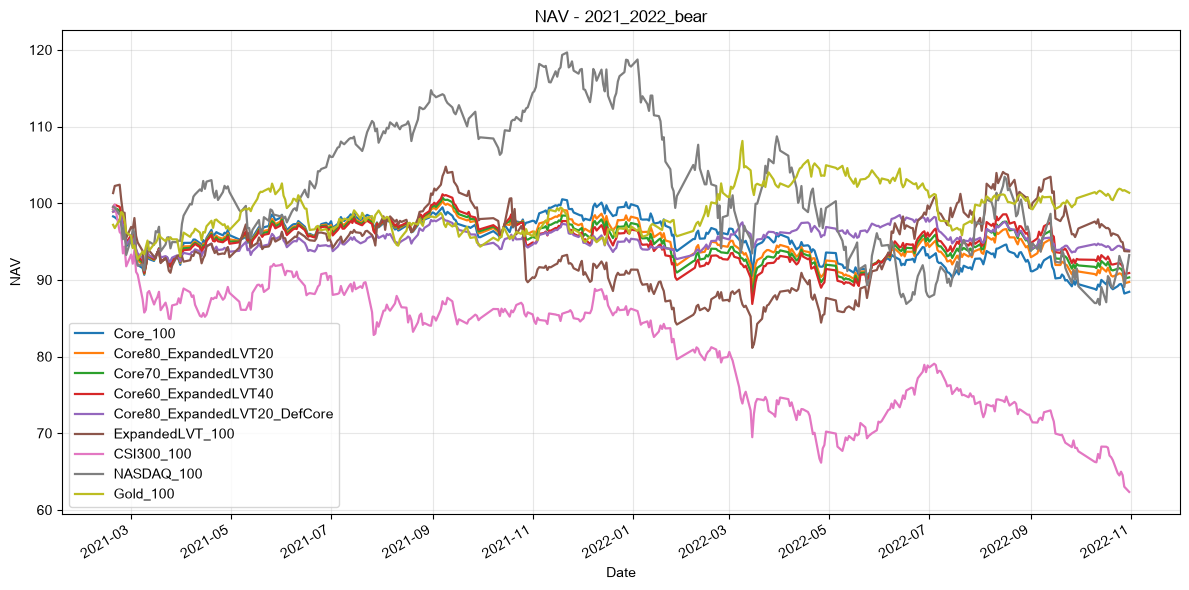

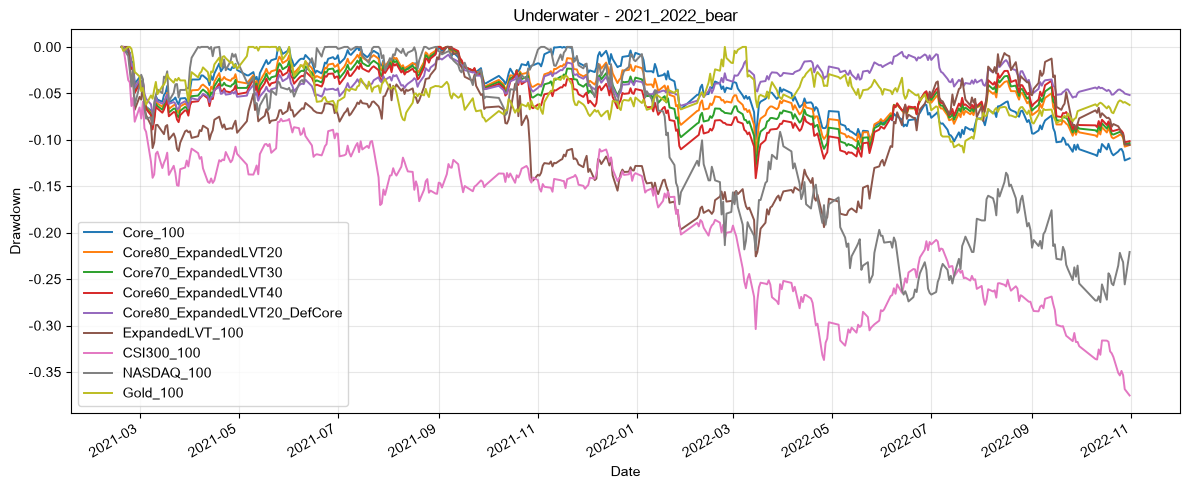

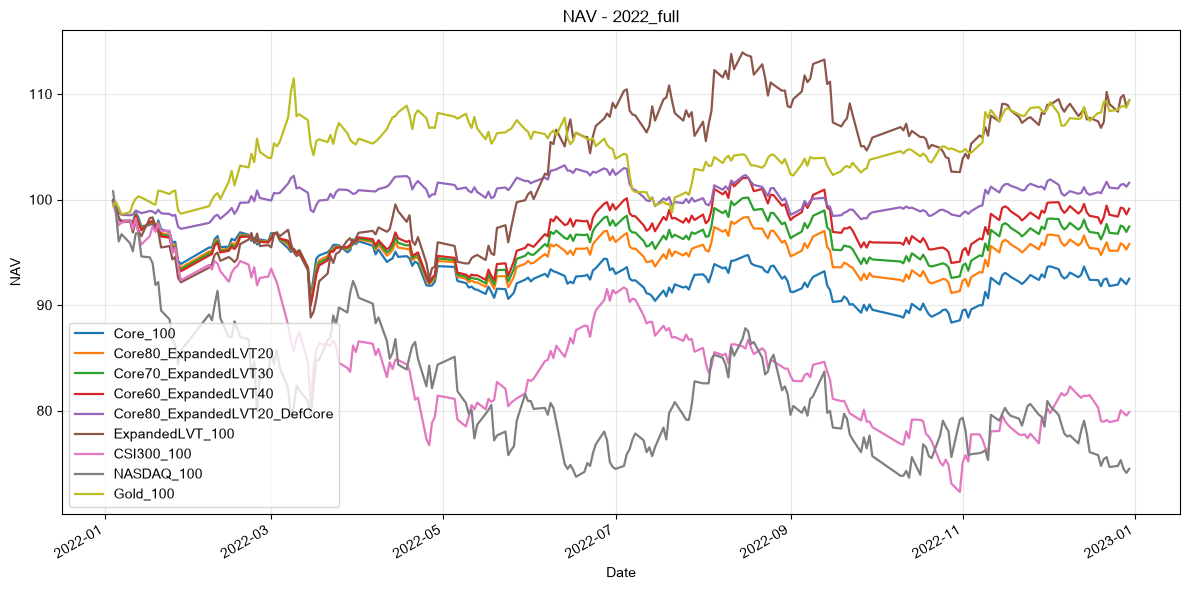

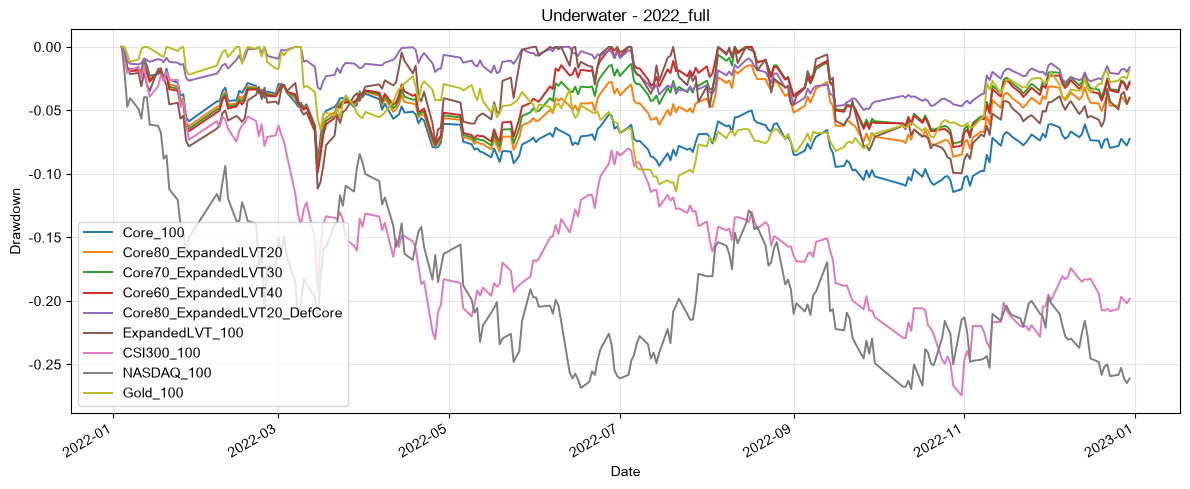

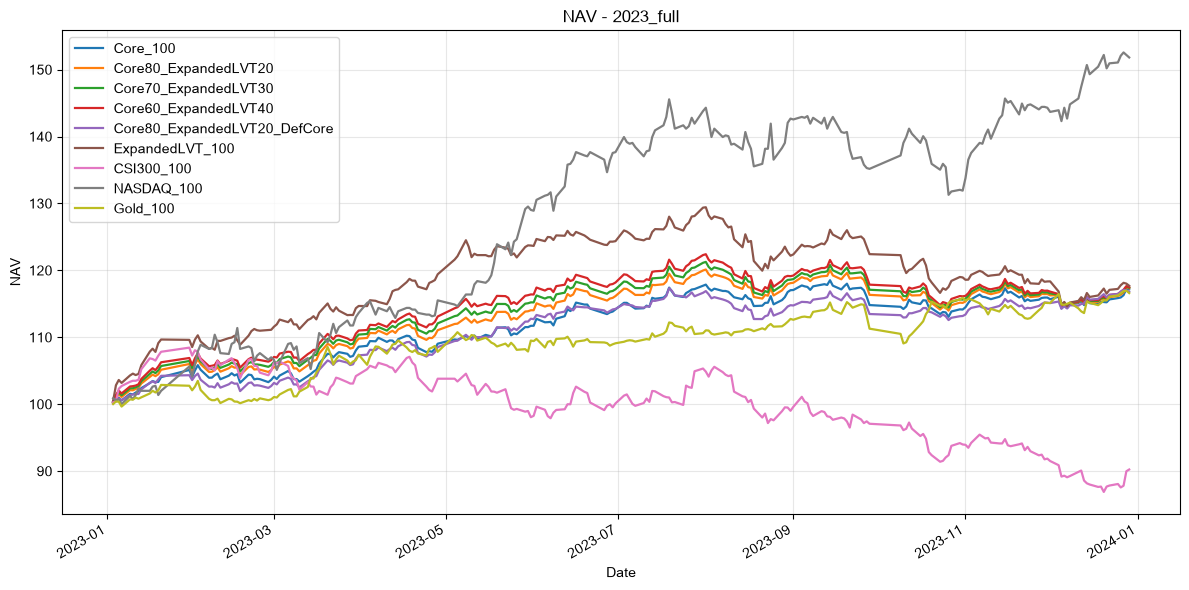

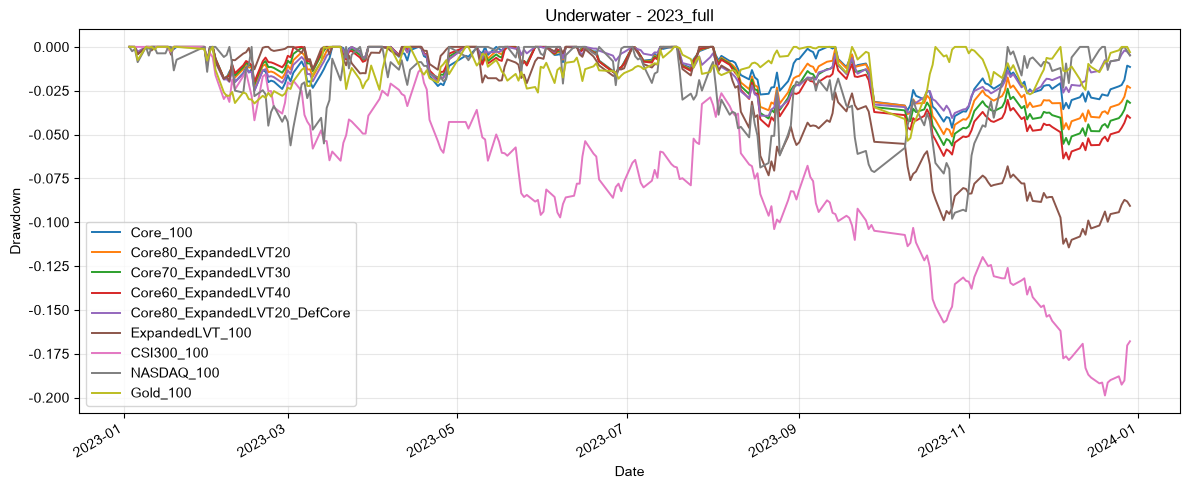

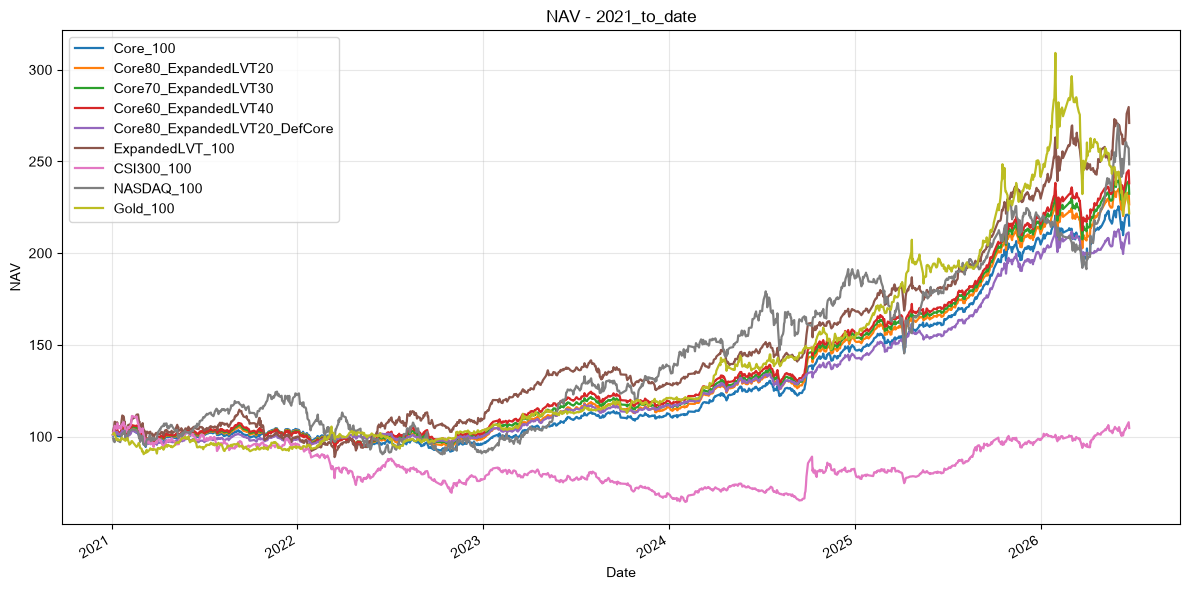

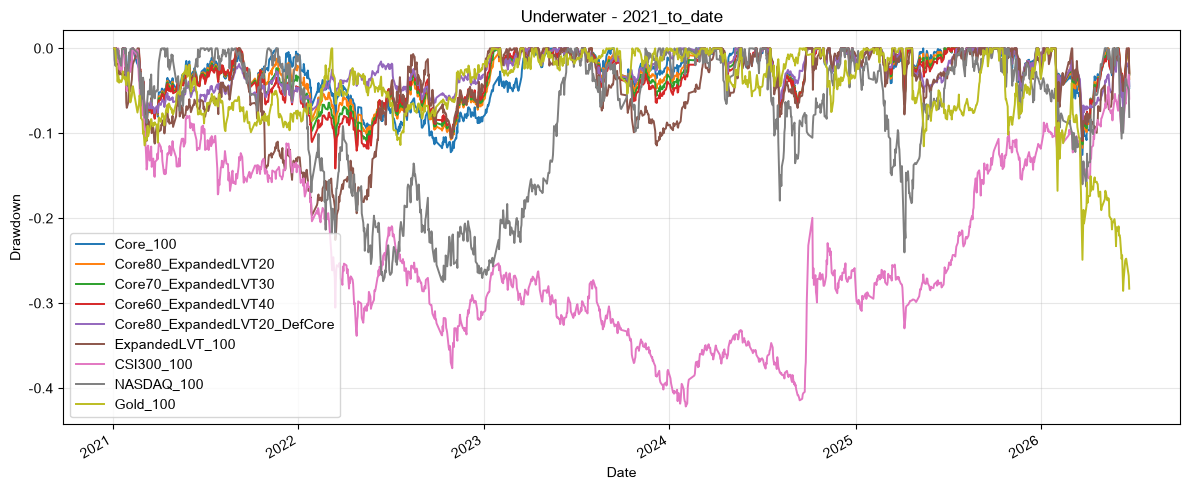

In [9]:
plot_strategies = ["Core_100", "Core80_ExpandedLVT20", "Core70_ExpandedLVT30", "Core60_ExpandedLVT40", "Core80_ExpandedLVT20_DefCore", "ExpandedLVT_100", "CSI300_100", "NASDAQ_100", "Gold_100"]
for window_name in ["2021_2022_bear", "2022_full", "2023_full", "2021_to_date"]:
    nav_df = nav_tables[window_name][plot_strategies]
    uw_df = underwater_tables[window_name][plot_strategies]
    fig, ax = plt.subplots(figsize=(12, 6))
    nav_df.plot(ax=ax, linewidth=1.6)
    ax.set_title(f"NAV - {window_name}")
    ax.set_ylabel("NAV")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"nav_{window_name}.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    uw_df.plot(ax=ax, linewidth=1.4)
    ax.set_title(f"Underwater - {window_name}")
    ax.set_ylabel("Drawdown")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"underwater_{window_name}.png", dpi=160)
    plt.show()

## Research Summary

In [10]:
research_summary = pd.DataFrame([
    {
        "item": "q5_primary_question",
        "value": "Does expanded LVT and core/satellite survive bear-market stress?",
    },
    {
        "item": "bear_window_core_return",
        "value": summary_tables["2021_2022_bear"].loc["Core_100", "累计收益"],
    },
    {
        "item": "bear_window_core_max_dd",
        "value": summary_tables["2021_2022_bear"].loc["Core_100", "最大回撤"],
    },
    {
        "item": "bear_window_core80_lvt20_return",
        "value": summary_tables["2021_2022_bear"].loc["Core80_ExpandedLVT20", "累计收益"],
    },
    {
        "item": "bear_window_core80_lvt20_max_dd",
        "value": summary_tables["2021_2022_bear"].loc["Core80_ExpandedLVT20", "最大回撤"],
    },
    {
        "item": "bear_window_defcore_return",
        "value": summary_tables["2021_2022_bear"].loc["Core80_ExpandedLVT20_DefCore", "累计收益"],
    },
    {
        "item": "bear_window_defcore_max_dd",
        "value": summary_tables["2021_2022_bear"].loc["Core80_ExpandedLVT20_DefCore", "最大回撤"],
    },
    {
        "item": "bear_window_lvt_avg_cash",
        "value": cash_diagnostics.loc[cash_diagnostics["window"] == "2021_2022_bear", "avg_satellite_cash_daily"].iloc[0],
    },
    {
        "item": "bear_window_lvt_zero_selection_pct",
        "value": cash_diagnostics.loc[cash_diagnostics["window"] == "2021_2022_bear", "pct_zero_selection_rebalances"].iloc[0],
    },
])
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary)

,item,value
0,q5_primary_question,Does expanded LVT and core/satellite survive b...
1,bear_window_core_return,-0.115543
2,bear_window_core_max_dd,-0.122262
3,bear_window_core80_lvt20_return,-0.102765
4,bear_window_core80_lvt20_max_dd,-0.115758
5,bear_window_defcore_return,-0.061474
6,bear_window_defcore_max_dd,-0.081668
7,bear_window_lvt_avg_cash,0.0
8,bear_window_lvt_zero_selection_pct,0.0


## Plain-Language Conclusion Placeholder

Read the exported tables before writing the final review note. The key check is whether the Q4 structure merely looked good in 2025, or whether it also avoids major damage in 2021-2022 and 2022.